## 💀️ Cat Scan Location Prediction

Given *data about various CAT scans*, let's try to predict the **location on the body** from where a given scan was taken.

We will use a TensorFlow/Keras neural network to make our predictions.

Data source: https://www.kaggle.com/datasets/uciml/ct-slice-localization

### Importing Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf

In [4]:
data = pd.read_csv('archive/slice_localization_data.csv')
data

,patientId,value0,value1,value2,value3,value4,value5,value6,value7,value8,...,value375,value376,value377,value378,value379,value380,value381,value382,value383,reference
0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,...,-0.25,0.980381,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.803851
1,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,...,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.745726
2,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,...,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.687600
3,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,...,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.629474
4,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,...,-0.25,0.976833,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.571348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53495,96,0.591906,0.357764,0.000000,0.000000,0.552321,0.795304,0.946697,0.952227,0.84395,...,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00,29.290398
53496,96,0.612313,0.000000,0.000000,0.000000,0.864160,0.820531,0.000000,0.938813,0.94374,...,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00,27.945721
53497,96,0.612313,0.000000,0.000000,0.000000,0.864160,0.820531,0.000000,0.938813,0.94374,...,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00,27.945721
53498,96,0.634921,0.904555,0.956087,0.980208,0.157664,0.000000,-0.250000,-0.250000,-0.25000,...,-0.25,0.000000,0.0,0.994967,0.806688,0.0,0.0,-0.25,-0.25,14.582997


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53500 entries, 0 to 53499
Columns: 386 entries, patientId to reference
dtypes: float64(385), int64(1)
memory usage: 157.6 MB


### Preprocessing

In [6]:
df = data.copy()

In [7]:
# Drop patienId column
df = df.drop('patientId', axis=1)
df

,value0,value1,value2,value3,value4,value5,value6,value7,value8,value9,...,value375,value376,value377,value378,value379,value380,value381,value382,value383,reference
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,-0.25,0.980381,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.803851
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.745726
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.687600
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.629474
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,-0.25,0.976833,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25,21.571348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53495,0.591906,0.357764,0.000000,0.000000,0.552321,0.795304,0.946697,0.952227,0.84395,0.798303,...,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00,29.290398
53496,0.612313,0.000000,0.000000,0.000000,0.864160,0.820531,0.000000,0.938813,0.94374,0.868504,...,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00,27.945721
53497,0.612313,0.000000,0.000000,0.000000,0.864160,0.820531,0.000000,0.938813,0.94374,0.868504,...,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00,27.945721
53498,0.634921,0.904555,0.956087,0.980208,0.157664,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,-0.25,0.000000,0.0,0.994967,0.806688,0.0,0.0,-0.25,-0.25,14.582997


In [8]:
# Split df into X and y
y = df['reference'].copy()
X = df.drop('reference', axis=1).copy()

In [9]:
y

0        21.803851
1        21.745726
2        21.687600
3        21.629474
4        21.571348
           ...    
53495    29.290398
53496    27.945721
53497    27.945721
53498    14.582997
53499    14.498955
Name: reference, Length: 53500, dtype: float64

In [10]:
X

,value0,value1,value2,value3,value4,value5,value6,value7,value8,value9,...,value374,value375,value376,value377,value378,value379,value380,value381,value382,value383
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,0.0,-0.25,0.980381,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,0.0,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,0.0,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,0.0,-0.25,0.977008,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,0.0,-0.25,0.976833,0.0,0.000000,0.000000,0.0,0.0,-0.25,-0.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53495,0.591906,0.357764,0.000000,0.000000,0.552321,0.795304,0.946697,0.952227,0.84395,0.798303,...,0.0,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00
53496,0.612313,0.000000,0.000000,0.000000,0.864160,0.820531,0.000000,0.938813,0.94374,0.868504,...,0.0,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00
53497,0.612313,0.000000,0.000000,0.000000,0.864160,0.820531,0.000000,0.938813,0.94374,0.868504,...,0.0,0.00,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.00,0.00
53498,0.634921,0.904555,0.956087,0.980208,0.157664,0.000000,-0.250000,-0.250000,-0.25000,-0.250000,...,0.0,-0.25,0.000000,0.0,0.994967,0.806688,0.0,0.0,-0.25,-0.25


In [11]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True, random_state=1)

In [13]:
X_train.describe()

,value0,value1,value2,value3,value4,value5,value6,value7,value8,value9,...,value374,value375,value376,value377,value378,value379,value380,value381,value382,value383
count,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,...,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000,37450.000000
mean,0.059190,0.071638,0.147057,0.218527,0.273778,0.275567,0.205600,0.062025,-0.043025,-0.231485,...,0.004943,-0.029206,0.183695,0.320226,0.359270,0.344180,0.265875,0.084800,-0.031221,-0.155017
std,0.173515,0.196934,0.301534,0.359447,0.378443,0.369504,0.352174,0.291662,0.267587,0.100615,...,0.075429,0.085841,0.383887,0.463548,0.478132,0.472092,0.437623,0.282430,0.097597,0.122500
min,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.250000,-0.250000,-0.250000,...,-0.250000,-0.250000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,-0.250000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,-0.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.250000
75%,0.000000,0.000000,0.000000,0.443693,0.679601,0.659500,0.449840,0.000000,0.000000,-0.250000,...,0.000000,0.000000,0.000000,0.996216,0.999686,0.999563,0.951105,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,0.998635,0.996468,0.999334,1.000000,1.000000,1.000000,...,0.998254,0.953475,1.000000,1.000000,1.000000,1.000000,1.000000,0.999848,0.996839,0.942851


### Training without scaling

In [14]:
X_train.shape

(37450, 384)

In [15]:
inputs = tf.keras.Input(shape=(384, ))
x = tf.keras.layers.Dense(128, activation='relu')(inputs)
x = tf.keras.layers.Dense(128, activation='relu')(x)
outputs = tf.keras.layers.Dense(1, activation='linear')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer='adam',
    loss='mse'
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=32,
    epochs=100,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )]
)

E0000 00:00:1792849309.791814    6891 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 121.8549 - val_loss: 21.2937
Epoch 2/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 12.1860 - val_loss: 8.0571
Epoch 3/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 5.9625 - val_loss: 4.7555
Epoch 4/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 3.7961 - val_loss: 3.9791
Epoch 5/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 2.8707 - val_loss: 2.9650
Epoch 6/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 2.2529 - val_loss: 2.7768
Epoch 7/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1.8057 - val_loss: 2.3862
Epoch 8/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 1.5656 - val_loss: 1.9379
Epoch 9/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 1.3266 - val_loss: 2.1661
Epoch 10/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1.3452 - val_loss: 1.7672
Epoch 11/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1.1335 - val_loss: 1.5179
Epoch 12/100
937/937 ━━━━━━━━━━━━━━━━

### Results

<Axes: ylabel='Frequency'>

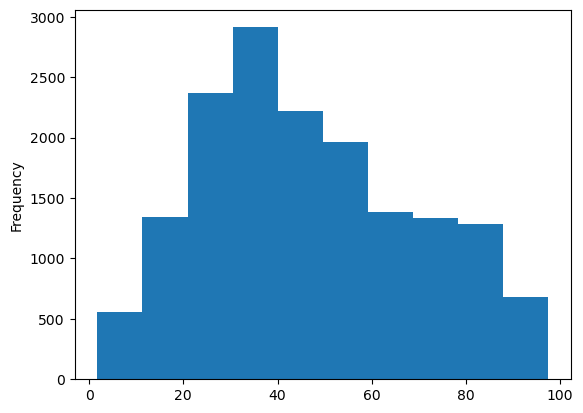

In [18]:
y_test.plot(kind='hist')

In [19]:
y_pred = model.predict(X_test)
y_pred

502/502 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[41.35903 ],
       [27.124882],
       [27.351055],
       ...,
       [28.187334],
       [82.72006 ],
       [35.62087 ]], shape=(16050, 1), dtype=float32)

In [20]:
y_pred.shape

(16050, 1)

In [22]:
y_pred = np.squeeze(y_pred)
y_pred

array([41.35903 , 27.124882, 27.351055, ..., 28.187334, 82.72006 ,
       35.62087 ], shape=(16050,), dtype=float32)

In [23]:
y_pred.shape

(16050,)

In [29]:
rmse = np.sqrt(np.mean((y_test - y_pred)**2))
print("RMSE: {:.4f}".format(rmse))

RMSE: 1.0971


In [32]:
np.sum((y_test - y_test.mean())**2)  # sum of squared errors of differences with respect to the baseline model

np.float64(8022031.62708539)

In [35]:
np.sum((y_test - y_pred)**2)  # sum of squared errors of differences with respect to the model predictions

np.float64(19318.801231054567)

In [39]:
r2 = 1 - np.sum((y_test - y_pred)**2) / np.sum((y_test - y_test.mean())**2)
print("R2 Score: {:.4f}".format(r2))

R2 Score: 0.9976


### Training with Scaling

In [40]:
# Split df into X and y
y = df['reference'].copy()
X = df.drop('reference', axis=1).copy()

In [41]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True, random_state=1)

In [42]:
# Scale X
scaler = StandardScaler()
scaler.fit(X_train)
X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [43]:
inputs = tf.keras.Input(shape=(384, ))
x = tf.keras.layers.Dense(128, activation='relu')(inputs)
x = tf.keras.layers.Dense(128, activation='relu')(x)
outputs = tf.keras.layers.Dense(1, activation='linear')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer='adam',
    loss='mse'
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=32,
    epochs=100,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )]
)

Epoch 1/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 98.2625 - val_loss: 17.6774
Epoch 2/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 10.4425 - val_loss: 7.0438
Epoch 3/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 5.4381 - val_loss: 5.3421
Epoch 4/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 3.7111 - val_loss: 3.1810
Epoch 5/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 2.8335 - val_loss: 3.1607
Epoch 6/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 2.4179 - val_loss: 2.8515
Epoch 7/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 2.1051 - val_loss: 2.5405
Epoch 8/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 1.9235 - val_loss: 2.4124
Epoch 9/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 1.5715 - val_loss: 1.8389
Epoch 10/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 1.4854 - val_loss: 2.0070
Epoch 11/100
937/937 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1.3672 - val_loss: 2.5286
Epoch 12/100
937/937 ━━━━━━━━━━━━━━━━━

In [44]:
y_pred = model.predict(X_test)
y_pred = np.squeeze(y_pred)

502/502 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [45]:
rmse = np.sqrt(np.mean((y_test - y_pred)**2))
print("RMSE: {:.4f}".format(rmse))

RMSE: 1.3131


In [46]:
r2 = 1 - np.sum((y_test - y_pred)**2) / np.sum((y_test - y_test.mean())**2)
print("R2 Score: {:.4f}".format(r2))

R2 Score: 0.9966
